<a href="https://colab.research.google.com/github/Ophelie4/pfizer-document-intelligence/blob/main/project-04-ocr-comparison-and-layout-extraction/notebooks/Ophelie_Scanned_SDF_OCR_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analyze a Scanned PDF with Tesseract OCR
Downloads `pharmaceutical-sdf-page2-animal-origin.pdf`, converts it to an image, applies preprocessing (grayscale, denoising, Otsu thresholding, rotation/deskew correction), runs Tesseract OCR with word-level bounding boxes, cleans the raw text, and structures the key fields (vendor, product, lot/doc info, dates, signatory) as JSON with bounding boxes.

In [ ]:
!apt-get -qq update > /dev/null
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip install -q pytesseract pymupdf opencv-python-headless gdown

import re
import json
import cv2
import numpy as np
import gdown
import fitz
import pytesseract
from pytesseract import Output
from matplotlib import pyplot as plt

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 69.3 MB/s eta 0:00:00


Downloading...
From: https://drive.google.com/uc?id=1YrWLSxMUK93DNflvWNOSdoOYjfmS7eM2
To: /content/sdf_page2.pdf
100%|██████████| 131k/131k [00:00<00:00, 52.3MB/s]


Image shape: (3300, 2550, 3)


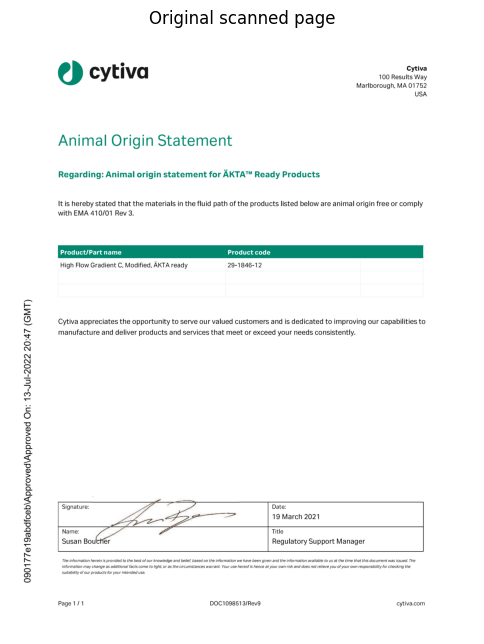

In [ ]:
# Download the scanned SDF page provided for this task
file_id = '1YrWLSxMUK93DNflvWNOSdoOYjfmS7eM2'
gdown.download(f'https://drive.google.com/uc?id={file_id}', 'sdf_page2.pdf', quiet=False)

# Convert the PDF page to an image at ~300 DPI (treat it as a scan, per the task)
pdf_doc = fitz.open('sdf_page2.pdf')
page0 = pdf_doc[0]
pix = page0.get_pixmap(matrix=fitz.Matrix(300 / 72, 300 / 72))
arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
img = cv2.cvtColor(arr, cv2.COLOR_RGBA2BGR) if pix.n == 4 else cv2.cvtColor(arr, cv2.COLOR_RGB2BGR)
print('Image shape:', img.shape)
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Original scanned page')
plt.show()

## Step 1: Preprocess the image to improve OCR accuracy

Detected skew angle: 0.25 degrees


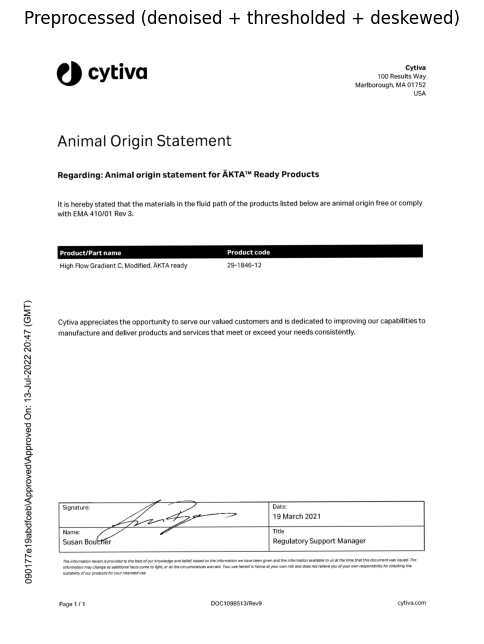

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Noise reduction
denoised = cv2.fastNlMeansDenoising(gray, None, h=10, templateWindowSize=7, searchWindowSize=21)

# Otsu thresholding (binarization)
_, binary = cv2.threshold(denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Rotation / deskew correction based on the bounding box of dark pixels
coords = np.column_stack(np.where(binary == 0))
angle = cv2.minAreaRect(coords)[-1]
if angle < -45:
    angle = -(90 + angle)
else:
    angle = -angle
(h, w) = binary.shape
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, angle, 1.0)
deskewed = cv2.warpAffine(binary, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

print(f'Detected skew angle: {angle:.2f} degrees')
plt.figure(figsize=(6, 8))
plt.imshow(deskewed, cmap='gray')
plt.axis('off')
plt.title('Preprocessed (denoised + thresholded + deskewed)')
plt.show()

## Step 2: Run Tesseract OCR (text + word-level bounding boxes)

In [ ]:
raw_text = pytesseract.image_to_string(deskewed)
print('--- RAW OCR TEXT ---')
print(raw_text)

ocr_data = pytesseract.image_to_data(deskewed, output_type=Output.DICT)
n_boxes = len(ocr_data['text'])
words = []
for i in range(n_boxes):
    text = ocr_data['text'][i].strip()
    conf = int(ocr_data['conf'][i]) if ocr_data['conf'][i] != '-1' else -1
    if text and conf > 30:
        x, y, w_, h_ = ocr_data['left'][i], ocr_data['top'][i], ocr_data['width'][i], ocr_data['height'][i]
        words.append({'text': text, 'conf': conf, 'bbox': [x, y, x + w_, y + h_]})

print(f'\nExtracted {len(words)} confident words')
for w in words[:15]:
    print(w)

--- RAW OCR TEXT ---
090177e19abdfceb\Approved\Approved On: 13-Jul-2022 20:47 (GMT)

@) cytiva wo eat

Marlborough, MA 01752
USA

Animal Origin Statement

Regarding: Animal origin statement for AKTA™ Ready Products

It is hereby stated that the materials in the fluid path of the products listed below are animal origin free or comply
with EMA 410/01 Rev 3.

Product/Part name Product code

High Flow Gradient C, Modified, AKTA ready 29-1846-12

Cytiva appreciates the opportunity to serve our valued customers and is dedicated to improving our capabilities to
manufacture and deliver products and services that meet or exceed your needs consistently.

Date:
19 March 2021

Title
Regulatory Support Manager

 

The information herein is provided to the best of our knowledge and belief, based on the information we have been given and the information available to us at the time that this document was issued. The
information may change as additional facts come to light, or as the circumstances warr

## Step 3: Clean the OCR output

In [ ]:
def clean_text(text):
    text = re.sub(r'[|]', 'I', text)                 # common Tesseract misread
    text = re.sub(r'\s+', ' ', text).strip()          # collapse whitespace
    text = text.replace('\u2122', 'TM')                # trademark symbol
    return text

cleaned_text = clean_text(raw_text)
print('--- CLEANED OCR TEXT ---')
print(cleaned_text)

--- CLEANED OCR TEXT ---
090177e19abdfceb\Approved\Approved On: 13-Jul-2022 20:47 (GMT) @) cytiva wo eat Marlborough, MA 01752 USA Animal Origin Statement Regarding: Animal origin statement for AKTATM Ready Products It is hereby stated that the materials in the fluid path of the products listed below are animal origin free or comply with EMA 410/01 Rev 3. Product/Part name Product code High Flow Gradient C, Modified, AKTA ready 29-1846-12 Cytiva appreciates the opportunity to serve our valued customers and is dedicated to improving our capabilities to manufacture and deliver products and services that meet or exceed your needs consistently. Date: 19 March 2021 Title Regulatory Support Manager The information herein is provided to the best of our knowledge and belief, based on the information we have been given and the information available to us at the time that this document was issued. The information may change as additional facts come to light, or as the circumstances warrant. Your

## Step 4: Locate key fields using anchor phrases + bounding boxes

In [ ]:
def find_value_right_of(anchor_words, all_words, y_tolerance=15, max_gap=400):
    """Find the anchor phrase (list of consecutive words) then grab words to its right on the same line."""
    n = len(anchor_words)
    for i in range(len(all_words) - n + 1):
        window = [w['text'].strip('.:').lower() for w in all_words[i:i + n]]
        if window == [a.lower() for a in anchor_words]:
            anchor_bbox = all_words[i:i + n]
            x1 = max(w['bbox'][2] for w in anchor_bbox)
            y0 = min(w['bbox'][1] for w in anchor_bbox)
            y1 = max(w['bbox'][3] for w in anchor_bbox)
            value_words = [w for w in all_words if w['bbox'][0] > x1 and w['bbox'][0] < x1 + max_gap
                            and abs(w['bbox'][1] - y0) < y_tolerance]
            value_words.sort(key=lambda w: w['bbox'][0])
            return anchor_bbox, value_words
    return None, []

fields = {}

# Vendor name (from the letterhead)
for w in words:
    if w['text'].lower().startswith('cytiva'):
        fields['vendor_name'] = {'value': 'Cytiva', 'bbox': w['bbox']}
        break

# Document type
anchor, _ = find_value_right_of(['Animal', 'Origin', 'Statement'], words)
if anchor:
    bbox = [min(w['bbox'][0] for w in anchor), min(w['bbox'][1] for w in anchor),
            max(w['bbox'][2] for w in anchor), max(w['bbox'][3] for w in anchor)]
    fields['document_type'] = {'value': 'Animal Origin Statement', 'bbox': bbox}

# Product code (regex: looks like 29-1846-12)
code_pattern = re.compile(r'\b\d{2}-\d{4}-\d{2}\b')
for w in words:
    if code_pattern.match(w['text']):
        fields['product_code'] = {'value': w['text'], 'bbox': w['bbox']}
        break

# Signature date
_, val = find_value_right_of(['Date:'], words)
if val:
    fields['signature_date'] = {'value': ' '.join(w['text'] for w in val[:3]),
                                 'bbox': [val[0]['bbox'][0], val[0]['bbox'][1], val[-1]['bbox'][2], val[-1]['bbox'][3]]}

# Signatory name
_, val = find_value_right_of(['Name:'], words)
if val:
    fields['signatory_name'] = {'value': ' '.join(w['text'] for w in val[:2]),
                                 'bbox': [val[0]['bbox'][0], val[0]['bbox'][1], val[-1]['bbox'][2], val[-1]['bbox'][3]]}

# Signatory title
_, val = find_value_right_of(['Title'], words)
if val:
    fields['signatory_title'] = {'value': ' '.join(w['text'] for w in val[:3]),
                                  'bbox': [val[0]['bbox'][0], val[0]['bbox'][1], val[-1]['bbox'][2], val[-1]['bbox'][3]]}

# Document reference number (regex: DOC followed by digits / Rev N)
doc_ref_pattern = re.compile(r'DOC\d+/?Rev\d*', re.IGNORECASE)
m = doc_ref_pattern.search(cleaned_text.replace(' ', ''))
if m:
    for w in words:
        if 'DOC' in w['text'].upper():
            fields['document_reference'] = {'value': m.group(0), 'bbox': w['bbox']}
            break

print(json.dumps(fields, indent=2))

{
  "vendor_name": {
    "value": "Cytiva",
    "bbox": [
      431,
      170,
      751,
      275
    ]
  },
  "document_type": {
    "value": "Animal Origin Statement",
    "bbox": [
      261,
      564,
      1214,
      644
    ]
  },
  "product_code": {
    "value": "29-1846-12",
    "bbox": [
      1192,
      1265,
      1377,
      1291
    ]
  },
  "document_reference": {
    "value": "DOC1098513/Rev9",
    "bbox": [
      1976,
      2887,
      2074,
      2903
    ]
  }
}


## Step 5: Save structured JSON output

In [ ]:
output = {
    'raw_ocr_text': raw_text,
    'cleaned_ocr_text': cleaned_text,
    'fields': fields,
}

with open('scanned_sdf_extraction.json', 'w') as f:
    json.dump(output, f, indent=2)

print('Saved scanned_sdf_extraction.json')
print(json.dumps(output, indent=2))

Saved scanned_sdf_extraction.json
{
  "raw_ocr_text": "090177e19abdfceb\\Approved\\Approved On: 13-Jul-2022 20:47 (GMT)\n\n@) cytiva wo eat\n\nMarlborough, MA 01752\nUSA\n\nAnimal Origin Statement\n\nRegarding: Animal origin statement for AKTA\u2122 Ready Products\n\nIt is hereby stated that the materials in the fluid path of the products listed below are animal origin free or comply\nwith EMA 410/01 Rev 3.\n\nProduct/Part name Product code\n\nHigh Flow Gradient C, Modified, AKTA ready 29-1846-12\n\nCytiva appreciates the opportunity to serve our valued customers and is dedicated to improving our capabilities to\nmanufacture and deliver products and services that meet or exceed your needs consistently.\n\nDate:\n19 March 2021\n\nTitle\nRegulatory Support Manager\n\n \n\nThe information herein is provided to the best of our knowledge and belief, based on the information we have been given and the information available to us at the time that this document was issued. The\ninformation may

## Step 6 (Optional): Visualize extracted fields with bounding boxes

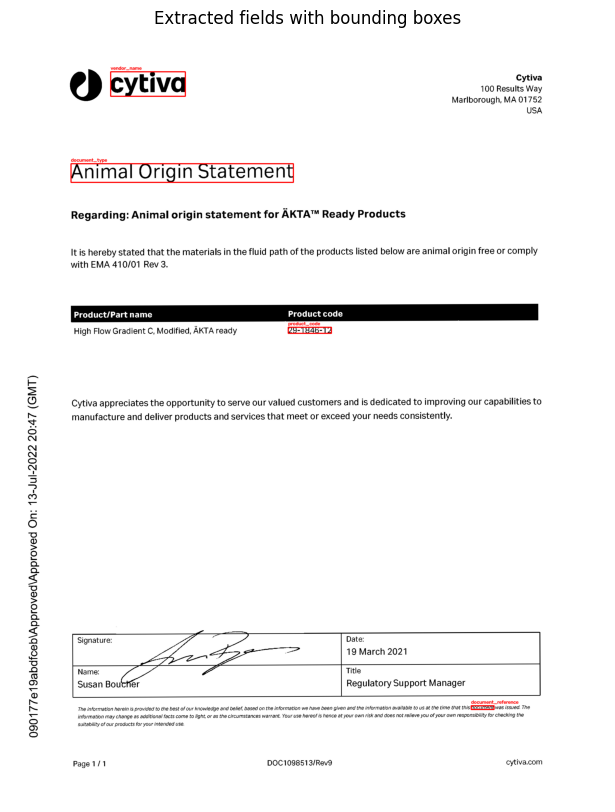

Saved scanned_sdf_annotated.jpg


In [ ]:
vis = cv2.cvtColor(deskewed, cv2.COLOR_GRAY2BGR)
for label, f in fields.items():
    x0, y0, x1, y1 = f['bbox']
    cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 0, 255), 3)
    cv2.putText(vis, label, (x0, max(y0 - 8, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)

cv2.imwrite('scanned_sdf_annotated.jpg', vis)
plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Extracted fields with bounding boxes')
plt.show()
print('Saved scanned_sdf_annotated.jpg')